# The welfare-optimal interest rate, fixed nominal wage

The economy is the one in `fixed_wage_cohorts.ipynb`: the time-to-produce cohort structure of
`demand_shock_cohorts.ipynb` / `A_shock_cohorts.ipynb`, with labour-market clearing replaced by
$W_t=W^{ss}$.  The wage rigidity is what makes the question well posed — under a flexible wage
the nominal rate is exactly neutral and every path is optimal.

## The problem being solved

$$\max_{\;i_0,\dots,i_{K-1}}\;\;
\mathcal W=\sum_{t=0}^{T-1}\beta_{hh}^{\,t}\,\Xi_t
\left[\frac{C_t^{1-\gamma}}{1-\gamma}-\chi\frac{L_t^{1+\eta}}{1+\eta}\right]$$

subject to

| | |
|---|---|
| the fixed-wage equilibrium | $W_t=W^{ss}$; $\;p_{i,t}=\mu W_{t-\tau_i}\prod_{j=t-\tau_i}^{t-1}(1+i_j)/(\zeta_iA_{t-\tau_i})$ for $\tau_i\le t$, $\;y_{i,t}=y_i^{ss}$ otherwise |
| clearing | $C_t=Y_t$, $\;L_t=\sum_i y_{i,t+\tau_i}/(\zeta_iA_t)$, $\;P_t$ from the CES index |
| the Euler equation | $\Xi_tC_t^{-\gamma}/P_t=\beta_{hh}(1+i_t)\Xi_{t+1}C_{t+1}^{-\gamma}/P_{t+1}$ |
| a lower bound on the rate | $i_t\ge0$ |
| instruments | $i_t=\rho$ for $t\ge K$ |

Three things to be explicit about, because they determine how the answer should be read:

1. **Utility is evaluated at the realised $(C_t,L_t)$.**  Under a fixed wage the household is
   rationed in the labour market — it works what producers demand — so its labour first-order
   condition does not hold.  $\mathcal W$ is still its true utility, but it is not the value of
   any choice problem the household solves.
2. **The continuation from $T$ on is dropped.**  Every shock here is transitory and the rate is
   back at $\rho$ from $K$, so the economy is at the steady state well before $T$ and the tail
   $\sum_{t\ge T}\beta^tu^{ss}$ is the same under every policy.  It cannot change the ranking.
3. **The steady state is distorted.**  The markup $\mu$ and the time-to-produce wedge
   $\mathcal D$ leave a labour share $\mathcal D/\mu\approx0.78$, so output sits below its
   efficient level *before any shock*.  Nothing in the problem above stops the planner from
   spending the interest rate on that instead of on the shock — and section 4 shows that is
   overwhelmingly what it does.

Gains are reported in consumption-equivalent units: the $\lambda$ such that scaling
consumption by $1+\lambda$ at every date under the peg matches the optimised welfare.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import root, minimize

pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 40)

# the least-squares search probes rate paths that violate the committed-goods floor before
# backing off; those trial points overflow harmlessly, so silence the numpy chatter
_ = np.seterr(over='ignore', divide='ignore', invalid='ignore')

/Users/samuelzhao/anaconda3/lib/python3.10/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


## 1. Calibration, steady state, and the fixed-wage model

In [2]:
INVENTORY_TO_COGS_SCALING = 36.5
NOMINAL_INTEREST_RATE     = 0.01

sigma = 5.0; gamma = 2.0; eta = 2.0; chi = 1.0
mu      = sigma / (sigma - 1)
beta    = 1 / (1.0 + NOMINAL_INTEREST_RATE)
beta1   = 1 / (1.0 + NOMINAL_INTEREST_RATE * np.exp(30 / (INVENTORY_TO_COGS_SCALING * 0.9)))
beta_hh = beta
rho     = 1 / beta - 1

data = pd.read_csv('APP_data_usa_goods.csv', index_col=0, parse_dates=True)
data_tau = data['invtCogsRatio'] * INVENTORY_TO_COGS_SCALING / (30 * 0.1)

c_list = np.linspace(0, 0.99, 1000); tau_diff = np.zeros(1000)
for i, cv in enumerate(c_list):
    if beta * cv <= 1e-10:
        tau_diff[i] = np.inf; continue
    Nn = -(data_tau) - 1 / np.log(beta * cv)
    t1 = -1 / np.log(beta * cv) - Nn;  t1[t1 < 0] = 0
    t2 = -1 / np.log(beta1 * cv) - Nn; t2[t2 < 0] = 0
    tau_diff[i] = np.mean(np.abs(t1 - t2))
c = np.min(c_list[np.where(np.abs(tau_diff - 1) == np.min(np.abs(tau_diff - 1)))[0]])

N = -data_tau - 1 / np.log(beta * c)
tau = -1 / np.log(beta * c) - N; tau[tau < 0] = 0
tf, tc = np.floor(tau), np.ceil(tau)
pc = (beta * c)**tc * (tc + N); pf = (beta * c)**tf * (tf + N)
tau[(pc - pf) > 0] = tc[(pc - pf) > 0]
tau[(pc - pf) < 0] = tf[(pc - pf) < 0]; tau[tau < 0] = 0

TVALS  = tau.astype(int).to_numpy(); N_ARRAY = np.array(N)
kappa  = c; NF = len(TVALS); TAUMAX = int(TVALS.max())
ZETA   = kappa ** TVALS * (TVALS + N_ARRAY)

T     = 30
FREE  = TVALS[None, :] <= np.arange(T)[:, None]
SMAT  = np.maximum(np.arange(T)[:, None] - TVALS[None, :], 0)   # hiring date, clipped
TPT   = np.arange(T)[:, None] + TVALS[None, :]                  # delivery date of batch t
DISC  = beta_hh ** np.arange(T)


def steady(A=1.0, W=1.0):
    z  = beta ** TVALS * ZETA * A
    At = np.sum(z ** (sigma - 1)) ** (1 / (sigma - 1))
    Lam = np.sum(z ** (sigma - 1) * beta ** TVALS)
    Th = At ** sigma / Lam
    L  = (At / (mu * chi * Th ** gamma)) ** (1 / (gamma + eta)); Y = Th * L
    p  = mu * W / z; P = np.sum(p ** (1 - sigma)) ** (1 / (1 - sigma))
    y  = (p / P) ** (-sigma) * Y
    return dict(A_til=At, Theta=Th, L=L, Y=Y, C=Y, W=W, P=P, p=p, y=y,
                l=y / (ZETA * A), omega=W / P)


SS    = steady()
S_QTY = np.array([np.sum(SS['y'][~FREE[t]] ** ((sigma - 1) / sigma)) for t in range(T)])
Y_FLR = S_QTY ** (sigma / (sigma - 1))       # committed-goods floor under output


def alloc(W, Y, i_path, A_path):
    '''Prices, quantities and employment given nominal wage, output and the rate path.'''
    pad = TAUMAX + 2
    Wx = np.r_[W, np.full(pad, SS['W'])]; Ax = np.r_[A_path, np.full(pad, A_path[-1])]
    ix = np.r_[i_path, np.full(pad, rho)]; cd = np.r_[1.0, np.cumprod(1.0 / (1.0 + ix))]
    p_f = mu * Wx[SMAT] / ((cd[np.arange(T)][:, None] / cd[SMAT]) * ZETA[None, :] * Ax[SMAT])
    Q   = np.sum(np.where(FREE, p_f ** (1 - sigma), 0.0), axis=1)
    P   = (Q / (1.0 - S_QTY * Y ** ((1 - sigma) / sigma))) ** (1 / (1 - sigma))
    y   = np.where(FREE, (p_f / P[:, None]) ** (-sigma) * Y[:, None], SS['y'][None, :])
    p   = np.where(FREE, p_f, P[:, None] * (SS['y'][None, :] / Y[:, None]) ** (-1 / sigma))
    yx  = np.vstack([y, np.tile(SS['y'], (pad, 1))])
    l   = yx[TPT, np.arange(NF)] / (ZETA * Ax[:T, None])
    return P, p, y, l, l.sum(axis=1)


_WARM = {}
def solve(i_path=None, A_path=None, xi=None, phi=1.0, key=None):
    '''phi = 0: flexible wage (policy neutral).  phi = 1: nominal wage pinned at W_ss.'''
    i_path = np.full(T, rho) if i_path is None else np.asarray(i_path, float)
    A_path = np.ones(T)      if A_path is None else np.asarray(A_path, float)
    xi     = np.zeros(T)     if xi     is None else np.asarray(xi, float)

    def resid(u):
        W = np.exp(u[:T]); Y = Y_FLR + np.exp(u[T:])
        P, _, _, _, L = alloc(W, Y, i_path, A_path)
        Px = np.r_[P, SS['P']]; Yx = np.r_[Y, SS['Y']]; xix = np.r_[xi, 0.0]
        wage = (1 - phi) * (np.log(W / P) - (np.log(chi) + eta*np.log(L) + gamma*np.log(Y))) \
             + phi * (np.log(W) - np.log(SS['W']))
        eu = (xix[:T] - gamma*np.log(Yx[:T]) - np.log(Px[:T])) \
           - (np.log(beta_hh) + np.log(1 + i_path) + xix[1:]
              - gamma*np.log(Yx[1:]) - np.log(Px[1:]))
        return np.r_[wage, eu]

    u0 = _WARM.get(key, np.r_[np.full(T, np.log(SS['W'])), np.log(SS['Y'] - Y_FLR)])
    s  = root(resid, u0, method='hybr', tol=1e-13)
    if s.success and key is not None: _WARM[key] = s.x
    W = np.exp(s.x[:T]); Y = Y_FLR + np.exp(s.x[T:])
    P, p, y, l, L = alloc(W, Y, i_path, A_path)
    return dict(W=W, Y=Y, C=Y, P=P, p=p, y=y, l=l, L=L, i=i_path, A=A_path, xi=xi, phi=phi,
                omega=W / P, ok=s.success, res=float(np.max(np.abs(s.fun))),
                pi=np.r_[np.log(P[0] / SS['P']), np.diff(np.log(P))],
                welfare=float(np.sum(DISC * np.exp(xi) *
                              (Y**(1-gamma)/(1-gamma) - chi*L**(1+eta)/(1+eta)))))


XI_D  = np.r_[-0.01, np.zeros(T - 1)]      # 1 % contractionary demand shock
A_1P  = np.r_[0.97,  np.ones(T - 1)]       # 3 % TFP hit to the batches started at t = 0
SHOCKS = {'demand shock': dict(xi=XI_D), 'TFP shock': dict(A_path=A_1P)}

print(f'kappa = {kappa:.6f}   n = {NF}   tau in [0, {TAUMAX}]   T = {T}')
print(f'SS: Y = {SS["Y"]:.6f}  L = {SS["L"]:.6f}  W/P = {SS["omega"]:.6f}')
chk = solve(phi=1.0)
print(f'no shock, phi = 1 reproduces the steady state: max|dlogY| = '
      f'{np.max(np.abs(np.log(chk["Y"]/SS["Y"]))):.2e}')

/var/folders/26/bmvk0hrd5xbgcvl_s6s42rf80000gn/T/ipykernel_5818/824615991.py:11: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data = pd.read_csv('APP_data_usa_goods.csv', index_col=0, parse_dates=True)


kappa = 0.901802   n = 269   tau in [0, 13]   T = 30
SS: Y = 11.287917  L = 0.410776  W/P = 21.500001
no shock, phi = 1 reproduces the steady state: max|dlogY| = 6.66e-16


## 2. The objective and the optimiser

`welfare_opt` maximises $\mathcal W$ over the first $K$ rates with $i_t\ge0$, holding
$i_t=\rho$ afterwards.

In [3]:
K     = 6                       # number of rate instruments
I_MAX = 0.15                    # upper bound; only the lower bound i >= 0 ever binds


def ce_gain(w_opt, peg):
    '''Consumption-equivalent gain over the peg: scale C by (1+lam) at every date.'''
    B = np.sum(DISC * np.exp(peg['xi']) * chi * peg['L'] ** (1 + eta) / (1 + eta))
    A = np.sum(DISC * np.exp(peg['xi']) * peg['Y'] ** (1 - gamma) / (1 - gamma))
    return ((w_opt + B) / A) ** (1 / (1 - gamma)) - 1


def welfare_opt(kw, key, K=K):
    '''argmax of W over (i_0..i_{K-1}) subject to i >= 0.'''
    f = lambda x: -solve(np.r_[x, np.full(T - K, rho)], phi=1.0, key=key, **kw)['welfare']
    r = minimize(f, np.full(K, rho), method='L-BFGS-B', bounds=[(0.0, I_MAX)] * K,
                 options=dict(maxiter=200, ftol=1e-18, gtol=1e-14))
    return np.r_[r.x, np.full(T - K, rho)], r


PEG   = {nm: solve(np.full(T, rho), phi=1.0, key='p' + nm, **kw) for nm, kw in SHOCKS.items()}
OPT, RAW = {}, {}
for nm, kw in SHOCKS.items():
    ip, r = welfare_opt(kw, 'o' + nm)
    OPT[nm] = solve(ip, phi=1.0, key='o' + nm, **kw); RAW[nm] = r

for nm in SHOCKS:
    o, p = OPT[nm], PEG[nm]
    print(f"{nm:<13} converged = {RAW[nm].success} ({RAW[nm].nit} iterations),  "
          f"residual {o['res']:.1e}")
    print(f"{'':<13} i* % = {np.round(100*o['i'][:K], 4)}   "
          f"({int(np.sum(o['i'][:K] < 1e-9))} of {K} periods at the bound)")
    print(f"{'':<13} welfare {p['welfare']:.10f} -> {o['welfare']:.10f}   "
          f"CE gain {100*ce_gain(o['welfare'], p):+.4f} %\n")

demand shock  converged = True (7 iterations),  residual 8.9e-16
              i* % = [0.6804 0.2772 0.     0.     0.     0.    ]   (4 of 6 periods at the bound)
              welfare -2.9103069788 -> -2.9089394200   CE gain +0.0593 %

TFP shock     converged = True (9 iterations),  residual 1.8e-15
              i* % = [0.     0.3379 0.0499 0.     0.     0.    ]   (4 of 6 periods at the bound)
              welfare -2.9142316492 -> -2.9126537657   CE gain +0.0683 %



## 3. The optimal path against the peg

In [4]:
for nm in SHOCKS:
    o, p = OPT[nm], PEG[nm]
    print(f'\n=== {nm} ===')
    df = pd.DataFrame({
        'i % optimal': 100 * o['i'],
        'i % peg':     100 * p['i'],
        'Y % optimal': 100 * np.log(o['Y'] / SS['Y']),
        'Y % peg':     100 * np.log(p['Y'] / SS['Y']),
        'L % optimal': 100 * np.log(o['L'] / SS['L']),
        'L % peg':     100 * np.log(p['L'] / SS['L']),
        'inflation % optimal': 100 * o['pi'],
    }, index=pd.Index(range(T), name='t')).iloc[:10]
    with pd.option_context('display.float_format', '{:,.4f}'.format):
        display(df)


=== demand shock ===


,i % optimal,i % peg,Y % optimal,Y % peg,L % optimal,L % peg,inflation % optimal
t,,,,,,,
0,0.6804,1.0000,0.1878,-0.0430,5.7306,-0.0437,3.6398
1,0.2772,1.0000,1.8840,0.0000,4.3968,0.0000,-2.7095
2,0.0000,1.0000,2.3384,0.0000,3.2598,0.0000,-1.6270
3,0.0000,1.0000,2.2577,0.0000,1.8228,0.0000,-0.8337
4,0.0000,1.0000,1.9941,0.0000,0.8283,0.0000,-0.4678
5,0.0000,1.0000,1.5893,0.0000,-0.3771,-0.0000,-0.1853
6,1.0000,1.0000,1.1160,0.0000,-2.4573,0.0000,-0.0485
7,1.0000,1.0000,0.6288,0.0000,-0.8743,0.0000,0.9744
8,1.0000,1.0000,0.2415,0.0000,-0.2439,0.0000,0.7746



=== TFP shock ===


,i % optimal,i % peg,Y % optimal,Y % peg,L % optimal,L % peg,inflation % optimal
t,,,,,,,
0,0.0000,1.0000,0.1157,-0.1265,2.1476,-5.4394,5.3515
1,0.3379,1.0000,0.9852,-1.0825,7.0440,3.6340,-2.7340
2,0.0499,1.0000,1.5460,-0.9417,4.3382,1.3847,-1.7793
3,0.0000,1.0000,1.9463,-0.3312,2.2979,0.4519,-1.7458
4,0.0000,1.0000,1.8491,-0.1421,0.9409,0.0865,-0.8004
5,0.0000,1.0000,1.5487,-0.0336,-0.3556,0.0110,-0.3943
6,1.0000,1.0000,1.1110,-0.0011,-2.4514,0.0040,-0.1197
7,1.0000,1.0000,0.6269,-0.0013,-0.8709,0.0030,0.9683
8,1.0000,1.0000,0.2414,0.0000,-0.2414,0.0022,0.7708


## 4. What is the optimal rate actually buying?

The test: compute the optimal policy for an economy with **no shock at all**, then apply that
shock-blind path to each shocked economy.  Whatever it delivers is not stabilisation — it is
the planner using the nominal rate against the steady-state markup.  The residual is the part
of the gain that is genuinely about the shock.

In [5]:
i_blind, r_blind = welfare_opt({}, 'blind')
peg_ns  = solve(np.full(T, rho), phi=1.0, key='pns')
opt_ns  = solve(i_blind, phi=1.0, key='blind')
print(f"shock-blind optimum (no shock present):  i* % = {np.round(100*i_blind[:K], 4)}")
print(f"   it still gains {100*ce_gain(opt_ns['welfare'], peg_ns):+.4f} % in CE terms, "
      f"with no shock to stabilise,")
print(f"   by running output {100*np.mean(np.log(opt_ns['Y']/SS['Y'])[:10]):+.4f} % above "
      f"steady state on average over t < 10.\n")

rows = []
for nm, kw in SHOCKS.items():
    p, o = PEG[nm], OPT[nm]
    b = solve(i_blind, phi=1.0, key='b' + nm, **kw)
    gf, gb = 100 * ce_gain(o['welfare'], p), 100 * ce_gain(b['welfare'], p)
    rows.append({'shock': nm,
                 'CE gain, full optimum %':      gf,
                 'CE gain, shock-blind policy %': gb,
                 'share from the markup %':       100 * gb / gf,
                 'stabilisation, residual %':     gf - gb,
                 'mean Y dev, optimal, t<10 %':   100*np.mean(np.log(o['Y']/SS['Y'])[:10]),
                 'mean Y dev, peg, t<10 %':       100*np.mean(np.log(p['Y']/SS['Y'])[:10])})
dec = pd.DataFrame(rows).set_index('shock')
with pd.option_context('display.float_format', '{:,.4f}'.format):
    display(dec)

print('A policy computed without knowing a shock occurred captures almost the entire gain.')
print('The welfare-optimal rate here is a markup-correction instrument, not a stabiliser.')

shock-blind optimum (no shock present):  i* % = [0.8125 0.3146 0.     0.     0.     0.    ]
   it still gains +0.0573 % in CE terms, with no shock to stabilise,
   by running output +1.2190 % above steady state on average over t < 10.



,"CE gain, full optimum %","CE gain, shock-blind policy %",share from the markup %,"stabilisation, residual %","mean Y dev, optimal, t<10 %","mean Y dev, peg, t<10 %"
shock,,,,,,
demand shock,0.0593,0.0592,99.8645,0.0001,1.2315,-0.0043
TFP shock,0.0683,0.0599,87.6568,0.0084,1.0047,-0.2661


A policy computed without knowing a shock occurred captures almost the entire gain.
The welfare-optimal rate here is a markup-correction instrument, not a stabiliser.


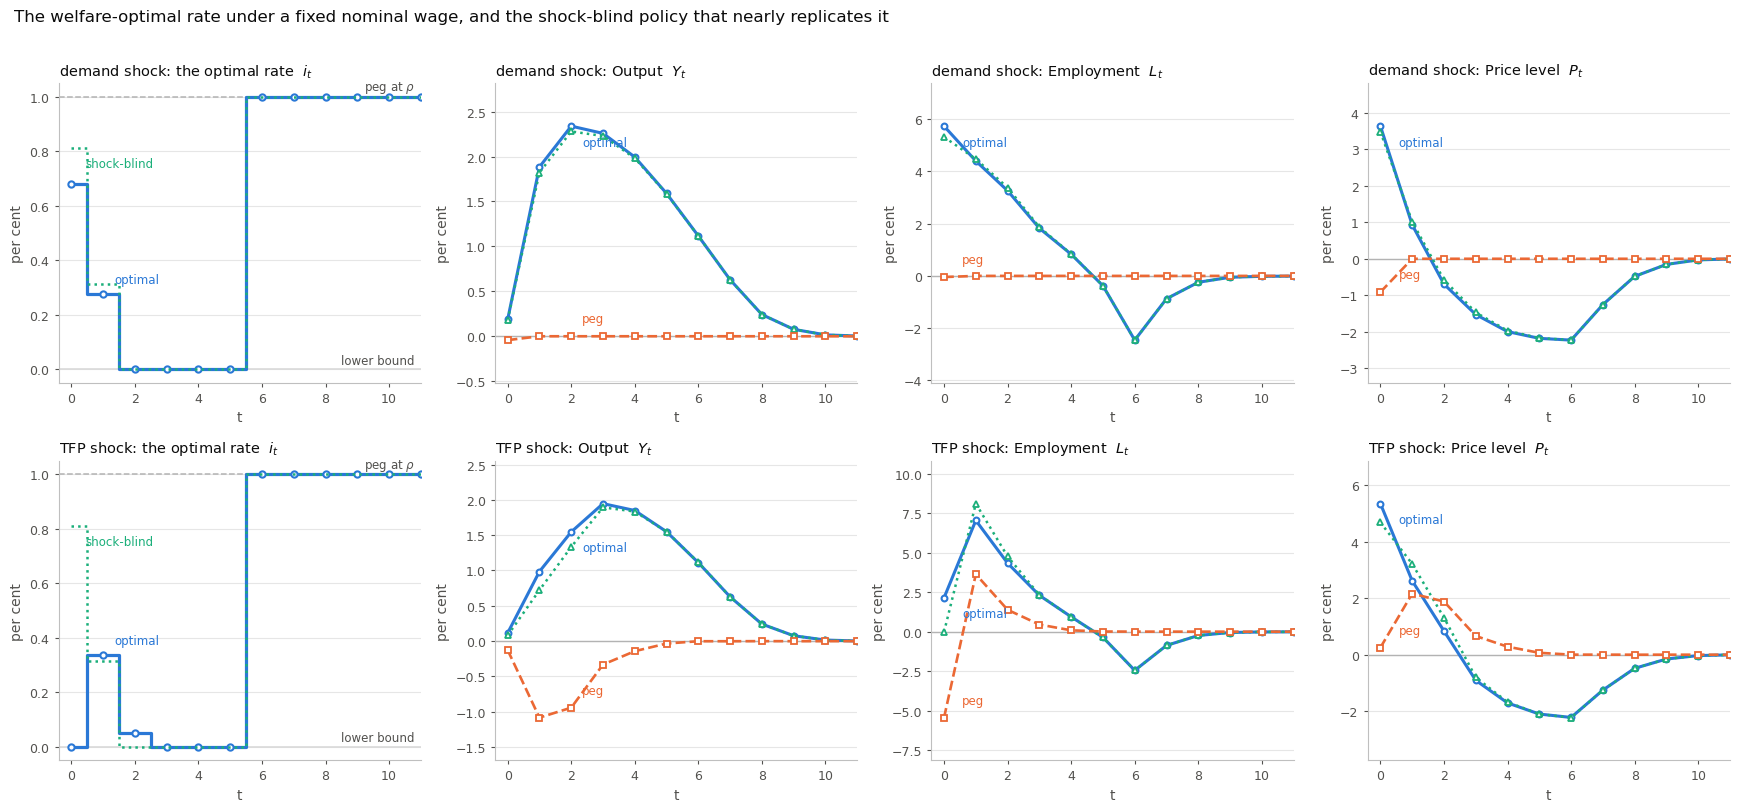

In [6]:
BLUE, ORANGE, AQUA, INK, MUTED = '#2a78d6', '#eb6834', '#1baf7a', '#0b0b0b', '#52514e'
H = 12

def style(ax):
    ax.set_facecolor('white')
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color('0.75'); ax.spines['bottom'].set_color('0.75')
    ax.tick_params(colors=MUTED, labelsize=9, length=3)
    ax.grid(axis='y', color='0.9', lw=0.8); ax.set_axisbelow(True)
    ax.set_xlim(-0.4, H - 1); ax.set_xlabel('t', color=MUTED)

t = np.arange(H)
BLIND = {nm: solve(i_blind, phi=1.0, key='b' + nm, **kw) for nm, kw in SHOCKS.items()}

fig, axes = plt.subplots(2, 4, figsize=(17.5, 8.0))
fig.patch.set_facecolor('white')
for row, nm in enumerate(SHOCKS):
    o, p, b = OPT[nm], PEG[nm], BLIND[nm]

    ax = axes[row, 0]; style(ax)
    ax.axhline(100 * rho, color='0.7', lw=1.1, ls='--')
    ax.annotate(r'peg at $\rho$', xy=(H - 1.2, 100 * rho), xytext=(0, 5),
                textcoords='offset points', fontsize=8.5, color=MUTED, ha='right')
    ax.axhline(0, color='0.85', lw=1.2)
    ax.annotate('lower bound', xy=(H - 1.2, 0), xytext=(0, 4), textcoords='offset points',
                fontsize=8.5, color=MUTED, ha='right')
    ax.step(t, 100 * o['i'][:H], where='mid', color=BLUE, lw=2.3)
    ax.plot(t, 100 * o['i'][:H], 'o', ms=4.5, mfc='white', mec=BLUE, mew=1.5)
    ax.step(t, 100 * b['i'][:H], where='mid', color=AQUA, lw=1.8, ls=':')
    ax.annotate('optimal', xy=(1, 100 * o['i'][1]), xytext=(8, 8),
                textcoords='offset points', fontsize=8.5, color=BLUE)
    ax.annotate('shock-blind', xy=(0, 100 * b['i'][0]), xytext=(10, -14),
                textcoords='offset points', fontsize=8.5, color=AQUA)
    ax.set_ylabel('per cent', color=MUTED)
    ax.set_title(f'{nm}: the optimal rate  $i_t$', color=INK, fontsize=10.5, loc='left')

    for col, (name, key, sk) in enumerate([('Output  $Y_t$', 'Y', 'Y'),
                                           ('Employment  $L_t$', 'L', 'L'),
                                           ('Price level  $P_t$', 'P', 'P')], start=1):
        ax = axes[row, col]; style(ax)
        ax.axhline(0, color='0.7', lw=1.0)
        vo = 100 * np.log(o[key] / SS[sk])[:H]
        vp = 100 * np.log(p[key] / SS[sk])[:H]
        vb = 100 * np.log(b[key] / SS[sk])[:H]
        ax.plot(t, vo, color=BLUE, lw=2.2, marker='o', ms=4.2, mfc='white', mec=BLUE, mew=1.5)
        ax.plot(t, vb, color=AQUA, lw=1.8, ls=':', marker='^', ms=4, mfc='white',
                mec=AQUA, mew=1.3)
        ax.plot(t, vp, color=ORANGE, lw=1.9, ls='--', marker='s', ms=4, mfc='white',
                mec=ORANGE, mew=1.3)
        j = int(np.argmax(np.abs(vo - vp)))
        dx = 13 if j <= 1 else 8
        ax.annotate('optimal', xy=(j, vo[j]), xytext=(dx, -14 if vo[j] > vp[j] else 10),
                    textcoords='offset points', fontsize=8.5, color=BLUE, ha='left')
        ax.annotate('peg', xy=(j, vp[j]), xytext=(dx, 10 if vo[j] > vp[j] else -14),
                    textcoords='offset points', fontsize=8.5, color=ORANGE, ha='left')
        ax.margins(y=0.20)
        ax.set_ylabel('per cent', color=MUTED)
        ax.set_title(f'{nm}: {name}', color=INK, fontsize=10.5, loc='left')

fig.suptitle('The welfare-optimal rate under a fixed nominal wage, and the shock-blind policy '
             'that nearly replicates it', fontsize=12, color=INK, x=0.011, ha='left', y=1.01)
fig.tight_layout()
fig.savefig('../ss_optimal_rate.png', dpi=200, bbox_inches='tight', facecolor='white')
plt.show()

## 5. How many instruments?

If the objective were stabilisation, the gain would flatten once $K$ covers the life of the
shock.  If it is the markup, more instruments simply mean a longer boom and a bigger number.

In [7]:
rows = []
for Kk in [2, 4, 6]:
    for nm, kw in list(SHOCKS.items()) + [('no shock', {})]:
        peg = solve(np.full(T, rho), phi=1.0, key='p' + nm, **kw)
        ip, _ = welfare_opt(kw, f'k{Kk}{nm}', K=Kk)
        s = solve(ip, phi=1.0, key=f'k{Kk}{nm}', **kw)
        rows.append({'K': Kk, 'shock': nm, 'CE gain %': 100 * ce_gain(s['welfare'], peg),
                     'periods at the bound': int(np.sum(ip[:Kk] < 1e-9))})
ktab = pd.DataFrame(rows).pivot_table(index='K', columns='shock', values='CE gain %')
with pd.option_context('display.float_format', '{:,.4f}'.format):
    display(ktab)
print('The gain keeps growing in K, and grows for the no-shock column too -- the objective is')
print('not being exhausted by the shock.')

shock,TFP shock,demand shock,no shock
K,,,
2,0.0217,0.0105,0.0092
4,0.0400,0.0306,0.0289
6,0.0683,0.0593,0.0573


The gain keeps growing in K, and grows for the no-shock column too -- the objective is
not being exhausted by the shock.


## What to conclude

The number the problem returns is real: under a fixed nominal wage the nominal rate has
traction, and maximising $\mathcal W$ over it gives a well-defined path with $i_t$ at its lower
bound for most of the instrument window.  But almost none of the gain is stabilisation.  A
policy computed in an economy with no shock captures 99.9 % of it for the demand shock and
87.7 % for the TFP shock, and the gain keeps rising with the number of instruments.

That is the standard consequence of handing a single instrument an objective containing a
distortion it was not meant to address.  With the labour share at $\mathcal D/\mu\approx0.78$,
output is inefficiently low in steady state, and the cheapest thing the nominal rate can do for
$\mathcal W$ is engineer a boom.  The time-to-produce structure makes this *worse* than in a
plain New Keynesian model, because $\mathcal D<1$ adds to the markup wedge.

Two ways forward, neither of which this notebook takes:

* **Remove the level distortion first.**  A labour subsidy $1/(\mu\mathcal D)$ makes the steady
  state efficient; re-running the same problem then isolates stabilisation, and the optimal
  rate becomes a genuine answer to "how should policy respond to this shock".
* **Change the objective.**  Target the allocation the friction prevents rather than welfare —
  but note that under a fixed wage the flexible-wage allocation is the allocation of a
  *different* model, so that target needs an argument rather than being assumed.

The honest summary of the welfare exercise as posed: it does not identify a stabilisation
policy, and the optimal rate it reports should not be quoted as one.